# Moroccan Traffic Sign Detection: dataset preparation and YOLO11n training

This notebook starts from the cleaned dataset produced by `data_preparation/01_…` to `06_…`, prepares it for YOLO
and trains the final model.

It was run on **Lightning AI** with an **NVIDIA Tesla T4 (16 GB)**. Paths under `/teamspace/studios/this_studio/`
come from that environment: change them to your own folders.

| Step | What it does |
|---|---|
| 1 | Download and unzip the cleaned dataset (Mapillary-style JSON labels) |
| 2 | Resize every image to 1024 × 1024 and scale the boxes accordingly |
| 3 | Drop images that contain a box flagged by Mapillary (occluded, out of frame, ambiguous, …) |
| 4 | Visual check of random samples |
| 5 | Balance classes: keep classes with ≥ 50 boxes, cap at 400, augment rare classes |
| 6 | Convert to YOLO format and split 80 / 10 / 10 |
| 7 | Cluster box sizes with K-Means++ |
| 8 | Train YOLO11n (1024 px, 130 epochs) |

**Final model:** 40 classes, 13,584 images (train 10,867 · val 1,358 · test 1,359).
Validation: precision 0.883 · recall 0.862 · mAP@50 **0.915** · mAP@50–95 **0.828**.

## 1. Download the cleaned dataset

In [ ]:
!pip install -q gdown

In [6]:
import gdown

# Google Drive file ID extracted from the link
file_id = "1HpODr5LBNKEntX-Ul2_5iwDc-l8tbJVS"
# URL format for gdown
url = f"https://drive.google.com/uc?id={file_id}"

# Output file name (optional; will default to original name if not provided)
output = "filtred_dataset.zip"  # change this to the appropriate file extension

# Download the file
gdown.download(url, output, quiet=False)


Downloading...
From (original): https://drive.google.com/uc?id=1HpODr5LBNKEntX-Ul2_5iwDc-l8tbJVS
From (redirected): https://drive.google.com/uc?id=1HpODr5LBNKEntX-Ul2_5iwDc-l8tbJVS&confirm=t&uuid=ba5e60cb-fc96-4c43-ade0-96f4add3b39c
To: /teamspace/studios/this_studio/filtred_dataset.zip
100%|██████████| 8.87G/8.87G [01:15<00:00, 118MB/s] 


'filtred_dataset.zip'

In [23]:
import zipfile
import os

# Path to your .zip file
zip_path = 'filtred_dataset.zip'  # replace with your zip filename

# Path where you want to extract the contents
extract_to = 'dataset'

# Make sure the destination folder exists
os.makedirs(extract_to, exist_ok=True)

# Extract the zip file
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print(f"✅ Files extracted to: {extract_to}")


✅ Files extracted to: dataset


## 2. Resize images to 1024 × 1024
Images and labels are overwritten in place; box coordinates are scaled to the new size.

In [25]:
import os
import cv2
import json
from tqdm import tqdm

# Paths (same input and output)
image_dir = r"/teamspace/studios/this_studio/dataset/images"
label_dir = r"/teamspace/studios/this_studio/dataset/labels"

# Target size (square)
target_size = 1024

def resize_image_and_json(img_path, json_path):
    # Load image
    img = cv2.imread(img_path)
    if img is None:
        print(f"⚠️ Could not read {img_path}")
        return None, None
    h, w = img.shape[:2]

    # Resize image
    resized_img = cv2.resize(img, (target_size, target_size))

    # Load JSON
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Update width and height
    data["width"] = target_size
    data["height"] = target_size

    # Update each bbox
    for obj in data.get("objects", []):
        bbox = obj.get("bbox", {})
        xmin = bbox.get("xmin", 0) * target_size / w
        ymin = bbox.get("ymin", 0) * target_size / h
        xmax = bbox.get("xmax", 0) * target_size / w
        ymax = bbox.get("ymax", 0) * target_size / h
        obj["bbox"] = {
            "xmin": xmin,
            "ymin": ymin,
            "xmax": xmax,
            "ymax": ymax
        }

    return resized_img, data

# Process all image files
image_files = [f for f in os.listdir(image_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

for filename in tqdm(image_files, desc="Processing"):
    name, _ = os.path.splitext(filename)
    img_path = os.path.join(image_dir, filename)
    json_path = os.path.join(label_dir, name + ".json")

    if not os.path.exists(json_path):
        print(f"⚠️ No label file for {filename}")
        continue

    resized_img, new_json = resize_image_and_json(img_path, json_path)
    if resized_img is None or new_json is None:
        continue

    # Overwrite original image
    cv2.imwrite(img_path, resized_img)

    # Overwrite original JSON
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(new_json, f, indent=2)

print("✅ All images and JSON labels resized to 1024x1024 in-place.")


Processing: 100%|██████████| 9351/9351 [09:24<00:00, 16.56it/s]

✅ All images and JSON labels resized to 1024x1024 in-place.


## 3. Drop images with flagged signs
Removes every image where at least one box has a Mapillary flag set to true (occluded, out of frame, ambiguous, included, dummy, …), so the model only learns from clearly visible signs.

In [26]:
import os
import json
from pathlib import Path
from tqdm import tqdm
import shutil

# Folders
images_dir = "/teamspace/studios/this_studio/dataset/images"
labels_dir = "/teamspace/studios/this_studio/dataset/labels"

# Condition: All properties must be False
def is_all_false(properties: dict) -> bool:
    return all(v is False for v in properties.values())

# Get all JSON files
label_files = [f for f in os.listdir(labels_dir) if f.endswith(".json")]

deleted_count = 0

for file_name in tqdm(label_files, desc="Filtering dataset"):
    label_path = os.path.join(labels_dir, file_name)

    with open(label_path, 'r') as f:
        data = json.load(f)

    objects = data.get("objects", [])
    
    # If any object has any property = True, delete both label and image
    if any(not is_all_false(obj["properties"]) for obj in objects):
        os.remove(label_path)

        # Remove corresponding image
        image_base = Path(file_name).stem
        for ext in [".jpg", ".jpeg", ".png"]:
            image_path = os.path.join(images_dir, image_base + ext)
            if os.path.exists(image_path):
                os.remove(image_path)
                break

        deleted_count += 1

print(f"\n✅ Done. Deleted {deleted_count} image-label pairs where at least one object had a property = True.")


Filtering dataset: 100%|██████████| 9351/9351 [00:02<00:00, 4360.25it/s]


✅ Done. Deleted 1571 image-label pairs where at least one object had a property = True.


## 4. Visual check
Random samples with their boxes.

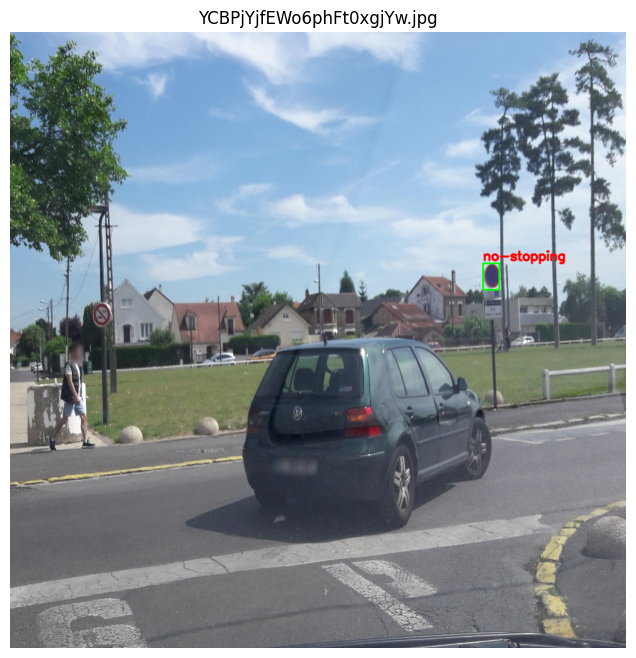

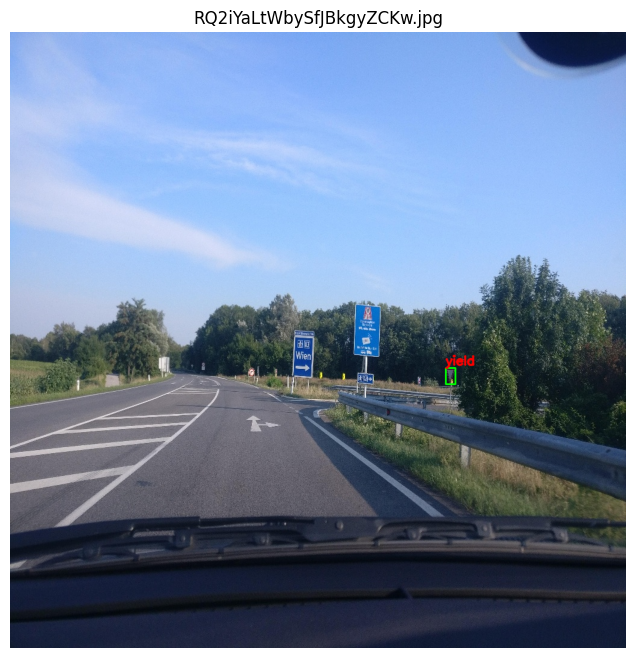

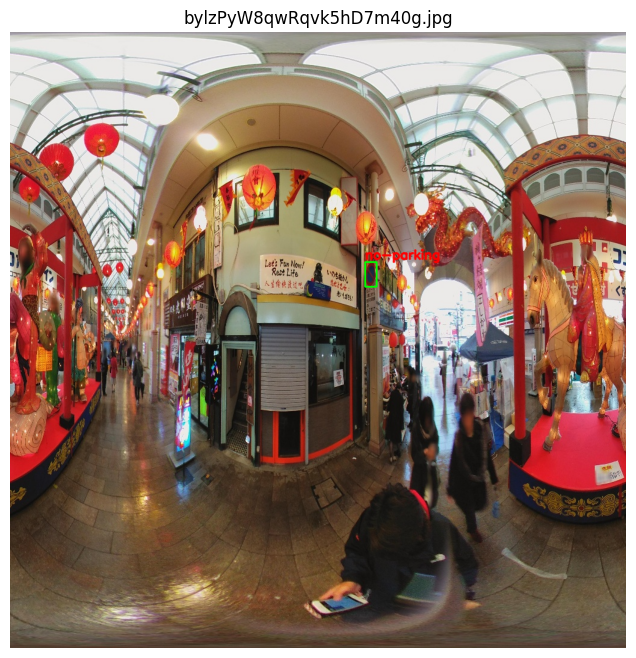

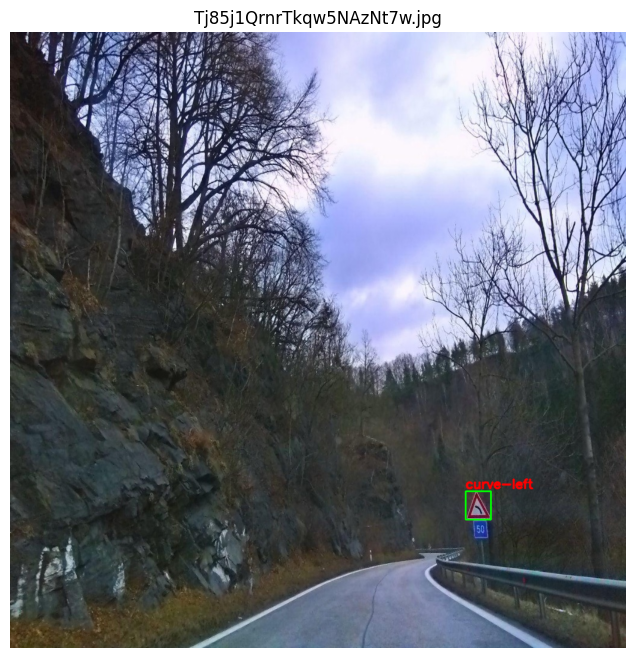

In [27]:
import os
import json
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Define folders (change if needed)
image_folder = "/teamspace/studios/this_studio/dataset/images"
label_folder = "/teamspace/studios/this_studio/dataset/labels"

# Get list of image files
image_files = [f for f in os.listdir(image_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Pick 10 random images
selected_images = random.sample(image_files, 10)

# Display images with bounding boxes
for img_name in selected_images:
    img_path = os.path.join(image_folder, img_name)
    label_path = os.path.join(label_folder, Path(img_name).stem + ".json")

    # Read image
    image = cv2.imread(img_path)
    if image is None:
        print(f"Cannot read image: {img_path}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Read label JSON
    if not os.path.exists(label_path):
        print(f"Missing label: {label_path}")
        continue

    with open(label_path, 'r') as f:
        data = json.load(f)

    # Draw bounding boxes and labels
    for obj in data.get("objects", []):
        label = obj["label"]
        bbox = obj["bbox"]
        xmin, ymin = int(bbox["xmin"]), int(bbox["ymin"])
        xmax, ymax = int(bbox["xmax"]), int(bbox["ymax"])

        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
        cv2.putText(image, label, (xmin, ymin - 5), cv2.FONT_HERSHEY_SIMPLEX, 
                    0.7, (255, 0, 0), 2, cv2.LINE_AA)

    # Display the image with bounding boxes
    plt.figure(figsize=(10, 8))
    plt.imshow(image)
    plt.title(img_name)
    plt.axis('off')
    plt.show()


## 5. Balance the classes
* keeps classes with at least **50** boxes
* undersamples frequent classes to **400** boxes
* augments rare classes up to 400 boxes with Albumentations: brightness/contrast, rotation (±15°), Gaussian blur

In [ ]:
!pip install -q opencv-python-headless albumentations pandas

In [28]:
import os
import json
import cv2
import random
import shutil
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import albumentations as A

# === CONFIG ===
images_dir = Path(r"/teamspace/studios/this_studio/dataset/images")
labels_dir = Path(r"/teamspace/studios/this_studio/dataset/labels")
output_images_dir = Path("balanced/images")
output_labels_dir = Path("balanced/labels")

min_allowed = 50
max_allowed = 400
augment_per_file = 20

output_images_dir.mkdir(parents=True, exist_ok=True)
output_labels_dir.mkdir(parents=True, exist_ok=True)

# === Count label frequency ===
label_counts = defaultdict(int)
file_label_map = defaultdict(list)

for json_file in tqdm(list(labels_dir.glob("*.json")), desc="Counting labels"):
    with open(json_file) as f:
        data = json.load(f)
        for obj in data.get("objects", []):
            label = obj["label"]
            label_counts[label] += 1
            file_label_map[json_file.name].append(label)

# === Filter valid labels
valid_labels = {k for k, v in label_counts.items() if v >= min_allowed}
print(f"Kept {len(valid_labels)} labels: {valid_labels}")

# === Build label-to-file map
label_file_map = defaultdict(list)
for file, labels in file_label_map.items():
    for label in labels:
        if label in valid_labels:
            label_file_map[label].append(file)

# === Undersample: keep up to max_allowed per label, without duplicating files
selected_files = set()
file_label_count = defaultdict(set)  # file: set(labels it is used for)

for label in valid_labels:
    files = list(set(label_file_map[label]))
    if len(files) > max_allowed:
        files = random.sample(files, max_allowed)
    for f in files:
        file_label_count[f].add(label)
    selected_files.update(files)

# === Copy selected files with only valid labels, with a post-filter after all labels
for file_name in tqdm(selected_files, desc="Copying valid files"):
    json_path = labels_dir / file_name
    img_path = images_dir / (json_path.stem + ".jpg")

    with open(json_path) as f:
        data = json.load(f)

    # Only keep objects with valid labels
    new_objects = [obj for obj in data["objects"] if obj["label"] in valid_labels]
    if not new_objects:
        continue

    data["objects"] = new_objects
    new_img_path = output_images_dir / img_path.name
    new_json_path = output_labels_dir / json_path.name

    if img_path.exists():
        shutil.copy(str(img_path), str(new_img_path))
        with open(new_json_path, "w") as f:
            json.dump(data, f, indent=2)

# === Recount after initial balancing
balanced_label_counts = defaultdict(int)
for json_file in output_labels_dir.glob("*.json"):
    with open(json_file) as f:
        data = json.load(f)
        for obj in data.get("objects", []):
            balanced_label_counts[obj["label"]] += 1

# === Rare labels to oversample
rare_labels = {k for k, v in balanced_label_counts.items() if v < max_allowed}
print(f"Rare labels to oversample: {rare_labels}")

# === Augmentation transform
transform = A.Compose([
    A.RandomBrightnessContrast(p=0.5),
    A.Rotate(limit=15, p=0.5),
    A.GaussianBlur(p=0.2)
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['category_ids']))

current_counts = dict(balanced_label_counts)

# Track which images have already been augmented for a label
augmented_for_label = defaultdict(set)  # label: set(filenames)

all_files = list(output_labels_dir.glob("*.json"))
for json_file in tqdm(all_files, desc="Augmenting rare labels"):
    with open(json_file) as f:
        data = json.load(f)

    img_path = output_images_dir / (json_file.stem + ".jpg")
    if not img_path.exists():
        continue

    image = cv2.imread(str(img_path))
    if image is None:
        continue
    height, width = image.shape[:2]

    # Only augment rare labels in this file which still need more
    objects = [obj for obj in data["objects"] if obj["label"] in rare_labels and current_counts[obj["label"]] < max_allowed]
    if not objects:
        continue

    bboxes = []
    labels = []
    for obj in objects:
        x1 = obj["bbox"]["xmin"]
        y1 = obj["bbox"]["ymin"]
        x2 = obj["bbox"]["xmax"]
        y2 = obj["bbox"]["ymax"]
        bboxes.append([x1, y1, x2, y2])
        labels.append(obj["label"])

    for i in range(augment_per_file):
        # Only continue if at least one label in this image is still under max
        if all(current_counts[label] >= max_allowed for label in labels):
            break

        try:
            augmented = transform(image=image, bboxes=bboxes, category_ids=labels)
        except Exception:
            continue

        aug_img = augmented["image"]
        aug_bboxes = augmented["bboxes"]
        aug_labels = augmented["category_ids"]

        if not aug_bboxes:
            continue

        new_objects = []
        for bbox, label in zip(aug_bboxes, aug_labels):
            # Only add this label if still under max
            if label in rare_labels and current_counts[label] < max_allowed:
                new_objects.append({
                    "key": "",
                    "label": label,
                    "bbox": {
                        "xmin": float(bbox[0]),
                        "ymin": float(bbox[1]),
                        "xmax": float(bbox[2]),
                        "ymax": float(bbox[3])
                    },
                    "properties": {}
                })
                current_counts[label] += 1
                if current_counts[label] >= max_allowed:
                    rare_labels.discard(label)  # stop augmenting this label

        if not new_objects:
            continue

        new_img_name = f"{json_file.stem}_aug{i}.jpg"
        new_json_name = f"{json_file.stem}_aug{i}.json"

        cv2.imwrite(str(output_images_dir / new_img_name), aug_img)

        new_json = {
            "width": aug_img.shape[1],
            "height": aug_img.shape[0],
            "ispano": False,
            "objects": new_objects
        }

        with open(output_labels_dir / new_json_name, "w") as jf:
            json.dump(new_json, jf, indent=2)

# === Final filter: Ensure no label exceeds max_allowed in the output set
final_label_counts = defaultdict(int)
for json_file in output_labels_dir.glob("*.json"):
    with open(json_file) as f:
        data = json.load(f)
    new_objects = []
    for obj in data["objects"]:
        label = obj["label"]
        if final_label_counts[label] < max_allowed:
            new_objects.append(obj)
            final_label_counts[label] += 1
    if len(new_objects) != len(data["objects"]):
        data["objects"] = new_objects
        with open(json_file, "w") as f:
            json.dump(data, f, indent=2)

print("\n✅ Dataset balanced and saved.")
print(f"Final label counts (capped at {max_allowed}):")
for label in sorted(final_label_counts):
    print(f"  {label}: {min(final_label_counts[label], max_allowed)}")

/home/zeus/miniconda3/envs/cloudspace/lib/python3.10/site-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.8' (you have '2.0.7'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
Counting labels: 100%|██████████| 7780/7780 [00:01<00:00, 4884.71it/s]


Kept 41 labels: {'keep-left', 'parking', 'double-curve-first-right', 'roundabout', 'no-parking', 'traffic-signals', 'maximum-speed-limit-20', 'stop', 'no-entry', 'road-bump', 'no-right-turn', 'no-stopping', 'no-heavy-goods-vehicles', 'no-left-turn', 'maximum-speed-limit-60', 'yield', 'end-of-speed-limit-zone', 'maximum-speed-limit-40', 'curve-left', 'maximum-speed-limit-30', 'go-straight', 'pedestrians-crossing', 'end-of-motorway', 'maximum-speed-limit-80', 'go-straight-or-turn-right', 'no-u-turn', 'pedestrians-only', 'keep-right', 'height-limit', 'bicycles-only', 'roadworks', 'Guide_Sign', 'one-way-right', 'children', 'crossroads', 'one-way-left', 'go-straight-or-turn-left', 'curve-right', 'no-overtaking', 'slippery-road-surface', 'other-danger'}


Copying valid files: 100%|██████████| 5832/5832 [00:14<00:00, 413.43it/s]


Rare labels to oversample: {'keep-left', 'parking', 'double-curve-first-right', 'roundabout', 'traffic-signals', 'maximum-speed-limit-20', 'road-bump', 'no-right-turn', 'no-heavy-goods-vehicles', 'no-left-turn', 'maximum-speed-limit-60', 'end-of-speed-limit-zone', 'maximum-speed-limit-40', 'curve-left', 'maximum-speed-limit-30', 'go-straight', 'end-of-motorway', 'maximum-speed-limit-80', 'go-straight-or-turn-right', 'no-u-turn', 'pedestrians-only', 'keep-right', 'height-limit', 'bicycles-only', 'roadworks', 'one-way-right', 'children', 'crossroads', 'one-way-left', 'go-straight-or-turn-left', 'curve-right', 'no-overtaking', 'slippery-road-surface', 'other-danger'}


Augmenting rare labels: 100%|██████████| 5432/5432 [02:21<00:00, 38.35it/s] 



✅ Dataset balanced and saved.
Final label counts (capped at 400):
  bicycles-only: 400
  children: 400
  crossroads: 400
  curve-left: 400
  curve-right: 400
  double-curve-first-right: 400
  end-of-motorway: 400
  end-of-speed-limit-zone: 400
  go-straight: 400
  go-straight-or-turn-left: 400
  go-straight-or-turn-right: 400
  height-limit: 400
  keep-left: 400
  keep-right: 400
  maximum-speed-limit-20: 400
  maximum-speed-limit-30: 400
  maximum-speed-limit-40: 400
  maximum-speed-limit-60: 400
  maximum-speed-limit-80: 400
  no-entry: 400
  no-heavy-goods-vehicles: 400
  no-left-turn: 400
  no-overtaking: 400
  no-parking: 400
  no-right-turn: 400
  no-stopping: 400
  no-u-turn: 400
  one-way-left: 400
  one-way-right: 400
  other-danger: 400
  parking: 400
  pedestrians-crossing: 400
  pedestrians-only: 400
  road-bump: 400
  roadworks: 400
  roundabout: 400
  slippery-road-surface: 400
  stop: 400
  traffic-signals: 400
  yield: 400


In [29]:
import os

# Define your folder paths
images_folder = 'balanced/images'
labels_folder = 'balanced/labels'

# Define supported file extensions
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')
label_extensions = ('.json',)  # assuming labels are in .txt format

# Count image files
image_files = [f for f in os.listdir(images_folder) if f.lower().endswith(image_extensions)]
label_files = [f for f in os.listdir(labels_folder) if f.lower().endswith(label_extensions)]

print(f"Number of images: {len(image_files)}")
print(f"Number of labels: {len(label_files)}")


Number of images: 13584
Number of labels: 13584


In [30]:
import os
import json
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt  # Optional for chart

# === CONFIG ===
labels_dir = Path(r"/teamspace/studios/this_studio/balanced/labels")  # <-- CHANGE THIS

# === Count occurrences of each label ===
label_counts = defaultdict(int)

for label_file in labels_dir.glob("*.json"):
    with open(label_file, "r") as f:
        data = json.load(f)
        for obj in data.get("objects", []):
            label = obj.get("label")
            if label:
                label_counts[label] += 1

# === Show results ===
total_labels = sum(label_counts.values())
print(f"Total labeled objects: {total_labels}")
# Write counts to a text file
with open("balanced/stats.txt", 'w') as f:
    for label, count in sorted(label_counts.items(), key=lambda x: x[1], reverse=True):
        f.write(f"{label}: {count}\n")

print("✅ Label counts saved stats.txt")

Total labeled objects: 16000
✅ Label counts saved stats.txt


## 6. Convert to YOLO format and split 80 / 10 / 10
Writes `final_dataset/` with `images/`, `labels/` (one `.txt` per image) and `data.yaml`.

In [31]:
import os
import json
import shutil
import random
from tqdm import tqdm

# === Config ===
dataset_root = r"/teamspace/studios/this_studio/balanced"  # ← your dataset path
images_dir = os.path.join(dataset_root, "images")
labels_dir = os.path.join(dataset_root, "labels")
output_root = r"/teamspace/studios/this_studio/final_dataset"  # <- corrected! Not a subdir of balanced

# Create necessary subdirectories
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(output_root, "images", split), exist_ok=True)
    os.makedirs(os.path.join(output_root, "labels", split), exist_ok=True)

# === Label map and counter ===
label_map = {}
class_id_counter = 0

def get_class_id(label):
    global class_id_counter
    if label not in label_map:
        label_map[label] = class_id_counter
        class_id_counter += 1
    return label_map[label]

# === Collect and shuffle data ===
json_files = [f for f in os.listdir(labels_dir) if f.endswith(".json")]
random.shuffle(json_files)

n = len(json_files)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

train_files = json_files[:n_train]
val_files = json_files[n_train:n_train+n_val]
test_files = json_files[n_train+n_val:]

def convert_files(json_list, split_name):
    for json_file in tqdm(json_list, desc=f"Processing {split_name}"):
        base_name = os.path.splitext(json_file)[0]
        json_path = os.path.join(labels_dir, json_file)

        # Match image file
        img_path_jpg = os.path.join(images_dir, base_name + ".jpg")
        img_path_png = os.path.join(images_dir, base_name + ".png")
        img_path = img_path_jpg if os.path.exists(img_path_jpg) else img_path_png

        if not os.path.exists(img_path):
            tqdm.write(f"⚠️ Image not found for {json_file}, skipping.")
            continue

        with open(json_path, "r") as f:
            data = json.load(f)

        width = data["width"]
        height = data["height"]
        yolo_lines = []

        for obj in data.get("objects", []):
            label = obj["label"]
            class_id = get_class_id(label)

            xmin = obj["bbox"]["xmin"]
            ymin = obj["bbox"]["ymin"]
            xmax = obj["bbox"]["xmax"]
            ymax = obj["bbox"]["ymax"]

            x_center = ((xmin + xmax) / 2) / width
            y_center = ((ymin + ymax) / 2) / height
            bbox_width = (xmax - xmin) / width
            bbox_height = (ymax - ymin) / height

            yolo_line = f"{class_id} {x_center:.6f} {y_center:.6f} {bbox_width:.6f} {bbox_height:.6f}"
            yolo_lines.append(yolo_line)

        # Write YOLO label
        label_output_path = os.path.join(output_root, "labels", split_name, base_name + ".txt")
        with open(label_output_path, "w") as out_file:
            out_file.write("\n".join(yolo_lines))

        # Copy image
        img_output_path = os.path.join(output_root, "images", split_name, os.path.basename(img_path))
        shutil.copy2(img_path, img_output_path)

# === Convert and split ===
convert_files(train_files, "train")
convert_files(val_files, "val")
convert_files(test_files, "test")

# === Generate data.yaml ===
data_yaml_path = os.path.join(output_root, "data.yaml")
with open(data_yaml_path, "w") as f:
    f.write(f"path: {output_root}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("test: images/test\n")
    f.write(f"nc: {len(label_map)}\n")
    f.write("names: [" + ", ".join(f"'{name}'" for name in label_map.keys()) + "]\n")

print("✅ YOLO dataset conversion and split complete!")

Processing test: 100%|██████████| 1359/1359 [00:02<00:00, 625.56it/s]

✅ YOLO dataset conversion and split complete!


## 7. Box-size clustering (K-Means++)
Clusters the width/height of the training boxes into 9 groups (small, medium and large signs).

YOLOv11 Anchor Format (to use in model.model.yaml['anchors']):
[[18.3, 24.52, 29.06, 38.8, 39.94, 55.64], [52.92, 73.8, 67.5, 96.82, 87.58, 126.5], [113.28, 162.02, 131.12, 246.01, 397.28, 441.0]]


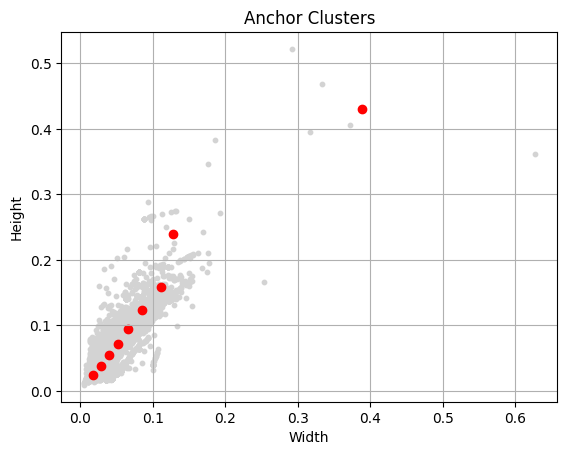

In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from tqdm import tqdm

# Settings
label_dir = 'final_dataset/labels/train'
k = 9  # total number of anchors (3 for each scale)
img_size = 1024  # image size used for training

bboxes = []

for label_file in os.listdir(label_dir):
    if not label_file.endswith('.txt'):
        continue
    with open(os.path.join(label_dir, label_file)) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            _, x_center, y_center, width, height = map(float, parts)
            bboxes.append([width, height])

bboxes = np.array(bboxes)

# KMeans clustering
kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10)
kmeans.fit(bboxes)
anchors = kmeans.cluster_centers_

# Sort anchors by area (width * height)
anchors = anchors[np.argsort(anchors[:, 0] * anchors[:, 1])]

# Scale anchors to image size
anchors_scaled = np.round(anchors * img_size, 2)

# Split into 3 groups (small, medium, large)
anchors_grouped = anchors_scaled.reshape(3, 3, 2).tolist()

# Format as YOLOv8 expects: 3 lists of 6 floats (w1, h1, w2, h2, w3, h3)
anchors_yolo_format = [[round(x, 2) for wh in scale for x in wh] for scale in anchors_grouped]

# Output
print("YOLOv11 Anchor Format (to use in model.model.yaml['anchors']):")
print(anchors_yolo_format)

# Optional: plot
plt.scatter(bboxes[:, 0], bboxes[:, 1], c='lightgray', s=10)
plt.scatter(anchors[:, 0], anchors[:, 1], c='red')
plt.title("Anchor Clusters")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid(True)
plt.show()


## 8. Train YOLO11n
Pretrained `yolo11n.pt`, 130 epochs, 1024 px images, batch 64, SGD (lr 0.01, weight decay 0.0005, 5 warm-up epochs).

In [ ]:
!pip install -q -U ultralytics

In [ ]:
from ultralytics import YOLO

# Load the pretrained YOLOv11n model
model = YOLO('yolo11n.pt')

# Set custom anchors
custom_anchors = [[18.3, 24.52, 29.06, 38.8, 39.94, 55.64], [52.92, 73.8, 67.5, 96.82, 87.58, 126.5], [113.28, 162.02, 131.12, 246.01, 397.28, 441.0]]
model.model.yaml['anchors'] = custom_anchors

# Enable hyperparameter evolution
training_params = {
    'data': '/teamspace/studios/this_studio/final_dataset/data.yaml',
    'epochs': 130,
    'batch': 64,               # choose 32 or 64 depending on your GPU memory
    'lr0': 0.01,               # initial learning rate
    'imgsz': 1024,              # image size for training
    'optimizer': 'SGD',        # SGD or Adam
    'weight_decay': 0.0005,    # regularization parameter
    'warmup_epochs': 5,        # warmup to stabilize
}

# Start evolution
model.train(**training_params)


WARNING ⚠️ Ultralytics settings reset to default values. This may be due to a possible problem with your settings or a recent ultralytics package update. 
View Ultralytics Settings with 'yolo settings' or at '/teamspace/studios/this_studio/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 5.35M/5.35M [00:00<00:00, 229MB/s]


Ultralytics 8.3.151 🚀 Python-3.10.10 torch-2.7.0+cu128 CUDA:0 (Tesla T4, 15102MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/teamspace/studios/this_studio/final_dataset/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=130, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=True, patience=100, perspective=0.0, plots=

train: Scanning /teamspace/studios/this_studio/final_dataset/labels/train... 10867 images, 225 backgrounds, 0 corrupt: 100%|██████████| 10867/10867 [00:06<00:00, 1595.87it/s]


train: New cache created: /teamspace/studios/this_studio/final_dataset/labels/train.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 132.5±61.8 MB/s, size: 329.2 KB)


val: Scanning /teamspace/studios/this_studio/final_dataset/labels/val... 1358 images, 18 backgrounds, 0 corrupt: 100%|██████████| 1358/1358 [00:01<00:00, 1071.82it/s]


val: New cache created: /teamspace/studios/this_studio/final_dataset/labels/val.cache
Plotting labels to runs/detect/train/labels.jpg... 


In [4]:
model.save('yolo11n_traffic_signs.pt')

## Results

The training log is not stored in this notebook; the metrics below are read from the saved model
(best epoch, validation split of 1,358 images).

| Precision | Recall | mAP@50 | mAP@50–95 |
|---:|---:|---:|---:|
| 0.883 | 0.862 | 0.915 | 0.828 |

Training curves: `results/training_metrics.png` and `results/training_losses.png`.